# Perturbed Equilibrium and 3D Response with GPEC

## Overview

This notebook is a first-draft shell for documenting perturbed equilibrium response analysis using GPEC; its last section, **NTV Torque and Coil Phasing** (#1887), is implemented and runs offline from a committed GPEC → PENTRC reference. It covers 3D coil signal inputs, non-axisymmetric response calculation, and visualization of perturbed equilibrium quantities.

## Objectives

- Define equilibrium and coil inputs required for GPEC response calculations.
- Organize 3D coil signal preparation and normalization conventions.
- Document non-axisymmetric response calculation outputs.
- Establish visualization and comparison products for perturbed equilibria.

## Expected Inputs

- Reconstructed equilibrium files and derived MHD equilibrium quantities.
- 3D coil geometry, current waveforms, phasing, and normalization metadata.
- GPEC configuration templates and optional DCON or RDCON stability outputs.
- Shot and time-slice selections from pipeline configuration.

## Expected Outputs

- GPEC input files and execution logs.
- Non-axisymmetric magnetic response quantities and synthetic diagnostic signals.
- Visualizations of perturbed equilibrium structure and 3D response fields.
- Comparison products for coil configurations, time slices, or scenarios.

## Pipeline Context

This notebook sits downstream of equilibrium reconstruction, MHD equilibrium analysis, and stability setup. In the Snakemake pipeline, it should provide reproducible GPEC response calculations and visualization products from versioned equilibrium and coil-input files.

## Main Section Headings

### GPEC Workflow Context

### Equilibrium Input Preparation

### 3D Coil Geometry and Signal Inputs

### Coil Phasing and Normalization

### Non-Axisymmetric Response Calculation

### Synthetic Diagnostic Signal Outputs

### 3D Response Visualization

### Scenario Comparison and Reporting

### Snakemake Rule Interface Draft

## Summary

This shell defines the initial organization for GPEC-based perturbed equilibrium and 3D response analysis. Implementation will later add input conversion, execution examples, visualization utilities, and comparison products.

## Open Implementation Tasks

- Confirm GPEC version, executable paths, and configuration requirements.
- Define 3D coil geometry and current input schemas.
- Add equilibrium-to-GPEC conversion and validation steps.
- Implement response visualization and synthetic diagnostic comparisons.
- Connect outputs to DCON, RDCON, and reporting stages.

## Related Notebooks

- `magnetic_equilibrium_reconstruction_with_efit.ipynb`
- `mhd_equilibrium_analysis.ipynb`
- `linear_ideal_stability_analysis_with_dcon.ipynb`
- `linear_resistive_stability_analysis_with_rdcon.ipynb`
- `fluctuation_diagnostics_analysis.ipynb`

## Requirements to run this page

This notebook is still a shell. It is not unimplemented for lack of a VAFT API:
it needs an external code that VAFT does not ship and cannot install for you.
What follows is what it takes to make it runnable, so the gap is a task rather
than a mystery.

### 1. Obtain GPEC

GPEC is not part of VAFT and cannot be installed from this repository. It is
obtained from its maintainers under their own terms and built locally; the build
story is tracked in
[#226](https://github.com/VEST-Tokamak/vaft/issues/226), which `install/README.md`
points to for exactly this reason. The VAFT installation scripts deliberately
cover the Python environment only.

### 2. Configure the root

```bash
export GPECHOME=/path/to/installation
```

The adapters resolve executables beneath that root:

  - `bin/gpec`
  - `bin/dcon (GPEC runs after DCON)`

`docs/_guide/Installation.md` section 4 documents this layout for every
supported code.

### 3. What VAFT already does without the binary

`vaft.code.gpec` prepares the case and reads every output format the suite
writes -- `_dcon_output`, `_gpec_output`, `_matching_output` and the netCDF
reader in `_netcdf` -- so results produced on another machine can be loaded and
analysed here without GPEC installed locally. The 3D coil description the
perturbed run needs is already in VAFT's machine mapping.

### 4. Check readiness before running anything

`notebooks/initialize_external_fusion_codes.ipynb` reports every configured root
and names the executables it could not find.
`vaft.code._executables.missing_home_message` produces the same message the
adapters raise, so a failure says which variable to set and which file was
expected rather than failing inside a solver.

### 5. What this page will show once GPEC is available

Its own Expected Outputs, above: the perturbed equilibrium and the 3D plasma
response to an applied field, including the resonant field amplification and the
surface response for a VEST case.


## NTV Torque and Coil Phasing (#1887)

Does the signed neoclassical toroidal viscosity (NTV) torque that PENTRC computes on a **fixed** plasma respond to the coil excitation as a Hermitian quadratic form,

$$T(\mathbf c) = \mathbf c^\dagger Q\,\mathbf c, \qquad c_g = A_g e^{+i\delta_g},\qquad I_k = A_g\cos(n\varphi_k + \delta_g)\ ?$$

If it does, $K^2$ direct runs determine $Q$, and every relative phase and amplitude of the $K$ coil groups follows from algebra. If it does not, the direct scan is the result. This section tests the hypothesis on real GPEC → PENTRC runs and uses $Q$ only once it qualifies.

**The case** is upstream GPEC's `docs/examples/DIIID_ideal_example`. It is an *artificial* TokaMaker DIII-D-like H-mode, **not DIII-D #147131**, which the GPEC checkout used here (e68d7ac2) does not contain.
- Toroidal mode $n = 1$; three coil groups `c`, `il`, `iu` with 6 coils each; one phasor unit = 1 kA per turn.
- PENTRC: ions only (D, with C impurity), `harmonic` collisions, methods fgar/tgar/pgar.
- The scalar is the signed enclosed torque at $\psi_N = 0.995$.
- The kinetic file carries $\omega_E$, not $\omega_\phi$.

The 22 runs (18 for the design, 4 to confirm the optima) are cached in `test/data/gpec/ntv_diiid_like_1887/scan.json`, so this section needs neither GPEC nor PENTRC. How to re-run them is at the end.

In [ ]:
import json
from pathlib import Path

import numpy as np

from vaft.process.ntv_coil_response import (
    fixed_amplitude_phase_extrema,
    hermitian_torque_matrix,
    ntv_operating_space,
    quadratic_invariance_checks,
    quadratic_torque,
    qualify_torque_matrix,
    two_group_phase_extrema,
)

_repo_root = Path.cwd()
if _repo_root.name == "notebooks":
    _repo_root = _repo_root.parent
REFERENCE = json.loads((_repo_root / "test" / "data" / "gpec" / "ntv_diiid_like_1887" / "scan.json").read_text())
SAMPLES = {row["sample_id"]: row for row in REFERENCE["samples"]}
GROUPS = REFERENCE["case"]["groups"]


def phasor(row):
    return np.asarray(row["c_re"]) + 1j * np.asarray(row["c_im"])


print(REFERENCE["case"]["description"])
print("roles:", {role: sum(r["role"] == role for r in REFERENCE["samples"]) for role in ("probe", "reference", "invariance", "held_out")})
print("converged tolerances:", REFERENCE["pentrc"]["tolerances"]["converged"])
print("default tolerances:  ", REFERENCE["pentrc"]["tolerances"]["default"])

upstream GPEC docs/examples/DIIID_ideal_example: an artificial TokaMaker DIII-D-like H-mode, NOT DIII-D #147131
roles: {'probe': 9, 'reference': 1, 'invariance': 4, 'held_out': 4}
converged tolerances: {'atol_xlmda': 1e-09, 'rtol_xlmda': 1e-07, 'atol_psi': 1e-06, 'rtol_psi': 1e-06}
default tolerances:   {'atol_xlmda': 1e-09, 'rtol_xlmda': 1e-06, 'atol_psi': 0.0001, 'rtol_psi': 0.0001}


### Qualification: identify $Q$ from the 9 probes, test it on points it never saw

The 9 probes ($e_i$, $e_i+e_j$, $e_i+i e_j$) determine $Q$ exactly, so matching them proves nothing. The test is on the other runs:
- **Without $Q$:** amplitude scaling $T(ac)=a^2T(c)$, sign reversal $T(-c)=T(c)$, and common-phase invariance.
- **Against $Q$:** 4 random held-out excitations plus the reference family.
- **Tolerance:** a sample passes when $|T_{\rm model}-T_{\rm direct}| \le$ 1 mN m + 2 % of $|T_{\rm direct}|$.

The same data are qualified twice: once at PENTRC's converged tolerances, once at the example's default tolerances.

In [ ]:
ATOL, RTOL = 1e-3, 0.02
VALIDATION = ("held0", "held1", "held2", "held3", "ref", "ref_x2", "ref_rot1.2")


def qualify(key, method="fgar"):
    torque = {k: row[key][method] for k, row in SAMPLES.items()}
    q = hermitian_torque_matrix(torque, len(GROUPS))
    checks = quadratic_invariance_checks(
        torque["ref"], scaled=[(0.5, torque["ref_x0.5"]), (2.0, torque["ref_x2"])],
        reversed_torque=torque["ref_neg"], rotated=[(1.2, torque["ref_rot1.2"])], atol=ATOL, rtol=RTOL,
    )
    return qualify_torque_matrix(q, np.array([phasor(SAMPLES[k]) for k in VALIDATION]),
                                 [torque[k] for k in VALIDATION], atol=ATOL, rtol=RTOL, invariance_checks=checks)


QUALIFIED = {}
for key, label in (("torque_n_m", "converged"), ("torque_n_m_default_tolerance", "default")):
    result = qualify(key)
    QUALIFIED[label] = result
    print(f"{label:9s} PENTRC tolerances -> {result.status:9s}  eig(Q) = {np.round(result.eigenvalues, 4)} N m/kA^2")
    for check in result.checks:
        print(f"    {check.name:18s} {'pass' if check.passed else 'FAIL'}   max |dT| {check.max_abs_error:.2e} N m"
              f"   max rel {check.max_rel_error:7.3%}")

converged PENTRC tolerances -> qualified  eig(Q) = [0.0022 0.0154 1.135 ] N m/kA^2
    amplitude_scaling  pass   max |dT| 9.90e-05 N m   max rel  0.006%
    sign_reversal      pass   max |dT| 0.00e+00 N m   max rel  0.000%
    common_phase       pass   max |dT| 3.65e-05 N m   max rel  0.008%
    held_out           pass   max |dT| 5.58e-04 N m   max rel  0.034%
default   PENTRC tolerances -> rejected   eig(Q) = [-0.0311  0.0134  1.1504] N m/kA^2
    amplitude_scaling  FAIL   max |dT| 7.31e-03 N m   max rel  6.622%
    sign_reversal      pass   max |dT| 0.00e+00 N m   max rel  0.000%
    common_phase       pass   max |dT| 1.26e-03 N m   max rel  0.286%
    held_out           FAIL   max |dT| 2.12e-01 N m   max rel 12.333%


At the example's default tolerances ($\texttt{atol\_psi}=\texttt{rtol\_psi}=10^{-4}$), small and cancelling torques are off by several percent. As a result:
- amplitude scaling fails;
- held-out errors reach about 12 %;
- $Q$ even looks indefinite.

At converged tolerances ($10^{-6}$, $\texttt{rtol\_xlmda}=10^{-7}$; a still tighter check agrees to within 0.024 %), every test passes, held-out errors are at most 0.03 %, and $Q$ is positive definite. So the quadratic model holds here, and the apparent nonlinearity was PENTRC integration error.

The practical rule: **check that PENTRC has converged before qualifying or rejecting any operating-space model.**

### Optima, then back through GPEC → PENTRC

The issue requires every optimum the model predicts to be re-run directly. Two cases:
- **Three groups at fixed 1 kA amplitudes:** a deterministic phase grid plus local polish (`fixed_amplitude_phase_extrema`).
- **`c` and `il` only:** the analytic answer $\Delta\varphi_{\max} = -\arg Q_{12}$.

In [ ]:
Q = QUALIFIED["converged"].Q
three = fixed_amplitude_phase_extrema(Q, (1, 1, 1), grid_points=72, refine=3)
two = two_group_phase_extrema(Q[:2, :2], (1, 1))
print(f"3 groups, A = 1 kA: max {three['T_max']:.4f} N m at phases {np.round(np.degrees(three['phases_max']), 1)} deg")
print(f"                    min {three['T_min']:.4f} N m at phases {np.round(np.degrees(three['phases_min']), 1)} deg")
print(f"c + il, A = 1 kA:   max {two['T_max']:.4f} N m at dphi = {np.degrees(two['delta_phi_max']):.1f} deg,"
      f" min {two['T_min']:.4f} N m at {np.degrees(two['delta_phi_min']):.1f} deg")
print()
print(f"{'confirmation':12s} {'Q c':>9s} {'GPEC->PENTRC':>13s} {'difference':>11s}   [N m]")
for row in REFERENCE["confirmations"]:
    model, direct = float(quadratic_torque(Q, phasor(row))), row["torque_n_m"]["fgar"]
    print(f"{row['sample_id']:12s} {model:9.4f} {direct:13.4f} {model - direct:+11.1e}")

3 groups, A = 1 kA: max 3.3254 N m at phases [  0.  321.6  47.1] deg
                    min 0.0248 N m at phases [  0.   85.7 270.7] deg
c + il, A = 1 kA:   max 1.5042 N m at dphi = 321.4 deg, min 0.0745 N m at 141.4 deg

confirmation       Q c  GPEC->PENTRC  difference   [N m]
opt3_max        3.3254        3.3255    -1.2e-04
opt3_min        0.0248        0.0250    -1.5e-04
opt2_max        1.5042        1.5041    +5.0e-05
opt2_min        0.0745        0.0746    -2.0e-04


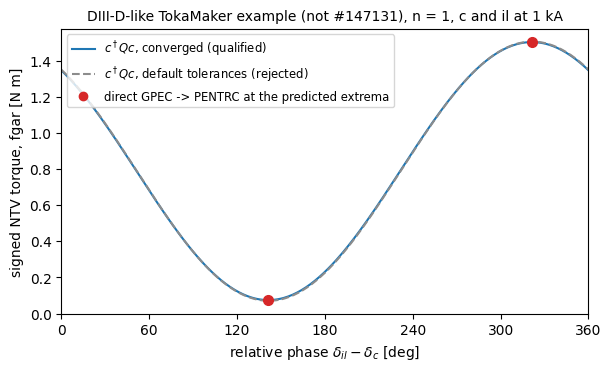

In [ ]:
import matplotlib.pyplot as plt

dphi = np.linspace(0.0, 2 * np.pi, 361)
sweep = np.stack([np.ones_like(dphi), np.exp(1j * dphi), np.zeros_like(dphi)], axis=1)  # c and il at 1 kA, iu off
fig, ax = plt.subplots(figsize=(6.0, 3.6), layout="constrained")
ax.plot(np.degrees(dphi), quadratic_torque(Q, sweep), color="C0", label=r"$c^\dagger Q c$, converged (qualified)")
ax.plot(np.degrees(dphi), quadratic_torque(QUALIFIED["default"].Q, sweep), color="0.55", ls="--",
        label=r"$c^\dagger Q c$, default tolerances (rejected)")
for row in REFERENCE["confirmations"]:
    if row["sample_id"].startswith("opt2"):
        c = phasor(row)
        ax.plot(np.degrees(np.mod(np.angle(c[1]) - np.angle(c[0]), 2 * np.pi)), row["torque_n_m"]["fgar"], "o",
                color="C3", ms=7, zorder=3)
ax.plot([], [], "o", color="C3", label="direct GPEC -> PENTRC at the predicted extrema")
ax.set_xlabel(r"relative phase $\delta_{il} - \delta_c$ [deg]")
ax.set_ylabel("signed NTV torque, fgar [N m]")
ax.set_xlim(0, 360)
ax.set_xticks(range(0, 361, 60))
ax.legend(fontsize="small")
ax.set_title("DIII-D-like TokaMaker example (not #147131), n = 1, c and il at 1 kA", fontsize="medium")
plt.show()

### In the common #1178 result

`ntv_operating_space` writes the direct torques, and the qualified model's predictions, into the shared `CoilOperatingSpace` (the schema agreed on #1886). The operating-space plots (#1886) and the resonant-response study (#1884) read this same object. Measured and modelled torques are separate metrics, and only `valid` rows carry numbers.

In [ ]:
rows = list(SAMPLES.values()) + REFERENCE["confirmations"]
space = ntv_operating_space(
    GROUPS, REFERENCE["case"]["n"], np.array([phasor(r) for r in rows]), [r["torque_n_m"]["fgar"] for r in rows],
    sample_ids=[r["sample_id"] for r in rows], roles=[r["role"] for r in rows],
    amplitude_unit=REFERENCE["case"]["phasor_unit_a_per_turn"], frame=REFERENCE["case"]["sector_angles"],
    provenance={"method": "fgar", "scalar": REFERENCE["pentrc"]["scalar"], **REFERENCE["pentrc"]["tolerances"]["converged"]},
    qualification=QUALIFIED["converged"],
)
frame = space.to_frame()
print(space.convention["phase_direction"])
frame.pivot_table(index="sample_id", columns="metric", values="value").join(
    frame.drop_duplicates("sample_id").set_index("sample_id")[["role", "amplitude_ratio_il", "phase_rel_il"]]
).round(4).head(12)

pattern peak at n phi = -delta: for n > 0, increasing delta rotates it toward -phi


           ntv_torque  ntv_torque_model      role  amplitude_ratio_il  \
sample_id                                                               
e0             0.5381            0.5381     probe              0.0000   
e0+e1          1.3478            1.3478     probe              1.0000   
e0+e2          1.4840            1.4840     probe              0.0000   
e0+ie1         0.3431            0.3431     probe              1.0000   
e0+ie2         1.5325            1.5325     probe              0.0000   
e1             0.2512            0.2512     probe                 NaN   
e1+e2          0.6633            0.6633     probe                 NaN   
e1+ie2         1.2115            1.2115     probe                 NaN   
e2             0.3633            0.3633     probe                 NaN   
held0          0.7659            0.7659  held_out              1.2814   
held1          1.0071            1.0071  held_out              0.5170   
held2          2.2884            2.2883  held_out  

### What this shows, and what it does not

- On this background, the signed NTV torque is a qualified Hermitian quadratic form of the coil phasors. Relative phasing alone moves it by more than two orders of magnitude at fixed currents: 0.025 to 3.33 N m.
- In the `c`–`il` plane of the figure the default-tolerance $Q$ happens to agree; its errors sit in the directions involving `iu` and in the cancelling held-out points, which is why only a held-out test catches them.
- $Q$ is positive definite here, so the torque never changes sign over this operating space. Nothing is called "braking" on the strength of a sign alone.
- The qualification holds only for this equilibrium and kinetic state, $n=1$, ion torque, ideal-GPEC displacement, PENTRC fgar/tgar/pgar, and amplitudes of 0.5–2 kA per turn per group.
  - VEST #48226 is a separate case, and so is the self-consistent kinetic-GPEC route (#1139).
  - The resonant-field objectives (#1884) are a separate operator on the same coordinates.

**Re-running the study.** It needs GPEC with `pentrc` installed (`install/install_gpec.sh` installs it into `$GPECHOME/bin` since #1883), and about 3–5 minutes per candidate on a laptop.

```bash
python workflow/gpec_ntv_coil_scan/scan_ntv_coil_torque.py --out runs/ntv1887 --design probes reference held_out --tolerance converged
python workflow/gpec_ntv_coil_scan/scan_ntv_coil_torque.py --out runs/ntv1887 --design confirm --from runs/ntv1887/scan_converged.json
```